In [2]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
%matplotlib inline

In [3]:
# read in all the words
words = open('names.txt', 'r').read().splitlines()
words[:8]

['emma', 'olivia', 'ava', 'isabella', 'sophia', 'charlotte', 'mia', 'amelia']

In [4]:
len(words)

32033

In [8]:
# build a vocabof characters and mappings to/from integers
chars = sorted(list(set(''.join(words))))
stoi = {s:i+1 for i,s in enumerate(chars)}
stoi['.'] = 0
itos = {i:s for s,i in stoi.items()}
print(itos)

{1: 'a', 2: 'b', 3: 'c', 4: 'd', 5: 'e', 6: 'f', 7: 'g', 8: 'h', 9: 'i', 10: 'j', 11: 'k', 12: 'l', 13: 'm', 14: 'n', 15: 'o', 16: 'p', 17: 'q', 18: 'r', 19: 's', 20: 't', 21: 'u', 22: 'v', 23: 'w', 24: 'x', 25: 'y', 26: 'z', 0: '.'}


In [108]:
# build the dataset

block_size = 3 # context length: how many characters do we take to predict the next one
X, Y = [], [] # X: input to the neural net, Y: labels for each example in X
for w in words:
    #print(w)
    context = [0] * block_size
    for ch in w + '.':
        idx = stoi[ch]
        X.append(context)
        Y.append(idx)
        #print(''.join(itos[i] for i in context), "-->", itos[idx])
        context = context[1:] + [idx] # crop and append

X = torch.tensor(X)
Y = torch.tensor(Y)

In [95]:
C = torch.randn((27, 2))
C

tensor([[-0.1805,  0.2754],
        [ 0.8322, -0.4016],
        [-0.3363,  1.9610],
        [-0.4101,  0.0169],
        [ 0.3114,  0.7035],
        [-0.1421,  0.0736],
        [ 1.1488,  1.2445],
        [ 1.0978, -0.7733],
        [-0.4445, -2.3068],
        [ 0.8457, -0.7469],
        [-1.9390, -1.0473],
        [-0.0734, -1.8451],
        [-0.0648, -0.1832],
        [ 1.3794,  0.2996],
        [-0.2385, -0.2440],
        [ 0.4651, -0.2214],
        [ 1.5237, -2.0702],
        [ 0.8578,  0.1212],
        [-0.9729, -0.2894],
        [-1.5117,  0.9330],
        [-0.4424,  0.0112],
        [-0.7333, -0.7955],
        [-0.5107,  0.9164],
        [ 1.5061,  0.9494],
        [-0.5125,  1.2628],
        [ 1.7812,  0.3376],
        [-0.2653, -0.1728]])

In [35]:
emb = C[X]
emb.shape

torch.Size([32, 3, 2])

In [36]:
# hidden layer
# 3 2D embeddings, 3*2=6
# Num of nuerons in hidden layer is up to us
W1 = torch.rand((6, 100))

# biases
b1 = torch.randn(100)

In [57]:
h = torch.tanh(emb.view(emb.shape[0], 6) @ W1 + b1)
h

tensor([[-0.9937, -0.9950, -0.9930,  ..., -0.9719, -0.9998, -0.9954],
        [-0.9826, -0.9950, -0.9974,  ..., -0.9919, -0.9993, -0.9987],
        [-0.9516, -0.9735, -0.9979,  ..., -0.9065, -0.9949, -0.9913],
        ...,
        [ 0.7313,  0.4246,  0.9578,  ...,  0.6874, -0.1744,  0.8632],
        [ 0.4543,  0.4732, -0.1793,  ...,  0.8941, -0.8548,  0.2386],
        [ 0.8391,  0.2066,  0.5863,  ..., -0.2264, -0.6335, -0.1783]])

In [58]:
h.shape

torch.Size([32, 100])

In [59]:
W2 = torch.rand((100, 27))
b2 = torch.randn(27)

In [60]:
logits = h @ W2 + b2

In [61]:
logits.shape

torch.Size([32, 27])

In [63]:
counts = logits.exp()

In [64]:
prob = counts / counts.sum(1, keepdims=True)

In [66]:
prob.shape

torch.Size([32, 27])

In [72]:
loss = -prob[torch.arange(32), Y].log().mean()
loss

tensor(6.0622)

## Now, lets organize this neetly

In [128]:
X.shape, Y.shape

(torch.Size([228146, 3]), torch.Size([228146]))

In [152]:
g = torch.Generator().manual_seed(2147483647) # for reproducibility
C = torch.randn((27, 2), generator=g)
W1 = torch.randn((6, 100), generator=g)
b1 = torch.randn(100, generator=g)
W2 = torch.randn((100, 27), generator=g)
b2 = torch.randn(27, generator=g)
parameters = [C, W1, b1, W2, b2]

In [111]:
sum(p.nelement() for p in parameters) # number of parameters in total

3481

In [99]:
emb = C[X] # (32, 3, 2)
h = torch.tanh(emb.view(-1, 6) @ W1 + b1) # (32, 100)
logits = h @ W2 + b2 # (32, 27)
counts = logits.exp()
prob = counts / counts.sum(1, keepdims=True)
loss = -prob[torch.arange(32), Y].log().mean()
loss

IndexError: shape mismatch: indexing tensors could not be broadcast together with shapes [32], [228146]

## We can actually write this even better...

In [ ]:
emb = C[X] # (32, 3, 2)
h = torch.tanh(emb.view(-1, 6) @ W1 + b1) # (32, 100)
logits = h @ W2 + b2 # (32, 27)
# counts = logits.exp()
# prob = counts / counts.sum(1, keepdims=True)
loss = F.cross_entropy(logits, Y)
loss

tensor(17.7697)

### Why is this better?
1. Efficiency - Memory; you're not creating all of the intermediary tensors. 

    `F.cross_entropy()` will cluster up all of these intermediary operations into a fused kernel

2. Stability - numerically, this built-in will handle setting of offset's to prevent overflow

    Internally `F.cross_entropy()` will calculate the max value that may occur in the tensor and subtract it to prevent overflow

In [153]:
for p in parameters:
    p.requires_grad = True

In [ ]:
learning_rate = -0.1

for _ in range(10):
    # forward pass
    emb = C[X] # (32, 3, 2)
    h = torch.tanh(emb.view(-1, 6) @ W1 + b1) # (32, 100)
    logits = h @ W2 + b2 # (32, 27)
    loss = F.cross_entropy(logits, Y)
    print(loss.item())

    # backward pass
    for p in parameters:
        p.grad = None
    loss.backward()

    # update
    for p in parameters:
        p.data += learning_rate * p.grad

10.709606170654297
10.407649040222168
10.127822875976562
9.86437702178955
9.614514350891113
9.376447677612305
9.14895248413086
8.931116104125977
8.722233772277832
8.521750450134277


## Note, that this goes kind of slow... 

This is becuase we're forwarding and backwarding 228k examples

In practice, devs perform forward, backward, and update on mini batches of the data

In [143]:
lr_exponent = torch.linspace(-3, 0, 1000) # 1000  numbers between -3, 0
lrs = 10**lr_exponent

In [162]:
# lr_i = []
# loss_i = []

for i in range(10000):
    # minibatch construct
    idx = torch.randint(0, X.shape[0], (32,))

    # forward pass
    emb = C[X[idx]] # (32, 3, 2)
    h = torch.tanh(emb.view(-1, 6) @ W1 + b1) # (32, 100)
    logits = h @ W2 + b2 # (32, 27)
    loss = F.cross_entropy(logits, Y[idx])
    #print(loss.item())

    # backward pass
    for p in parameters:
        p.grad = None
    loss.backward()

    # update
    # lr = lrs[i]
    lr = 0.01
    for p in parameters:
        p.data += -lr * p.grad

    # track stats
    # lr_i.append(lr_exponent[i])
    # loss_i.append(loss.item())


Text(0, 0.5, 'Loss')

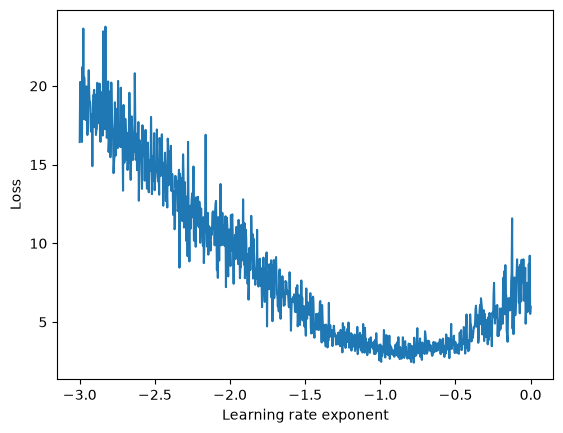

In [151]:
plt.plot(lr_i, loss_i)
plt.xlabel('Learning rate exponent')
plt.ylabel('Loss')

In [163]:
emb = C[X] # (32, 3, 2)
h = torch.tanh(emb.view(-1, 6) @ W1 + b1) # (32, 100)
logits = h @ W2 + b2 # (32, 27)
loss = F.cross_entropy(logits, Y)
loss

tensor(2.3186, grad_fn=<NllLossBackward0>)

## In practice, we partition our dataset

**training split** (80%) - used to train the model

**validation split** (10%) - used to train the hyperparameters (i.e. lr, hidden layer size, embedding size, etc.)

**test split (10%)** -  used to evaluate model at the very end

In [164]:
# build the dataset
block_size = 3 # context length: how many characters do we take to predict the next one?

def build_dataset(words):  
  X, Y = [], []
  for w in words:

    #print(w)
    context = [0] * block_size
    for ch in w + '.':
      ix = stoi[ch]
      X.append(context)
      Y.append(ix)
      #print(''.join(itos[i] for i in context), '--->', itos[ix])
      context = context[1:] + [ix] # crop and append

  X = torch.tensor(X)
  Y = torch.tensor(Y)
  print(X.shape, Y.shape)
  return X, Y

import random
random.seed(42)
random.shuffle(words)
n1 = int(0.8*len(words))
n2 = int(0.9*len(words))

Xtr, Ytr = build_dataset(words[:n1])
Xdev, Ydev = build_dataset(words[n1:n2])
Xte, Yte = build_dataset(words[n2:])

torch.Size([182625, 3]) torch.Size([182625])
torch.Size([22655, 3]) torch.Size([22655])
torch.Size([22866, 3]) torch.Size([22866])


In [182]:
Xtr.shape, Ytr.shape # dataset

(torch.Size([182625, 3]), torch.Size([182625]))

In [225]:
g = torch.Generator().manual_seed(2147483647) # for reproducibility
C = torch.randn((27, 10), generator=g)
W1 = torch.randn((30, 200), generator=g)
b1 = torch.randn(200, generator=g)
W2 = torch.randn((200, 27), generator=g)
b2 = torch.randn(27, generator=g)
parameters = [C, W1, b1, W2, b2]

In [226]:
sum(p.nelement() for p in parameters) # number of parameters in total

11897

In [227]:
for p in parameters:
  p.requires_grad = True

In [228]:
step_i = []
loss_i = []

In [229]:
for i in range(200000):
  
  # minibatch construct
  ix = torch.randint(0, Xtr.shape[0], (32,))
  
  # forward pass
  emb = C[Xtr[ix]] # (32, 3, 10)
  h = torch.tanh(emb.view(-1, 30) @ W1 + b1) # (32, 200)
  logits = h @ W2 + b2 # (32, 27)
  loss = F.cross_entropy(logits, Ytr[ix])
  #print(loss.item())
  
  # backward pass
  for p in parameters:
    p.grad = None
  loss.backward()
  
  # update
  lr = 0.1 if i < 100000 else 0.01
  for p in parameters:
    p.data += -lr * p.grad

  # track stats
  step_i.append(i)
  loss_i.append(loss.log10().item())

#print(loss.item())

Text(0, 0.5, 'Loss (log10)')

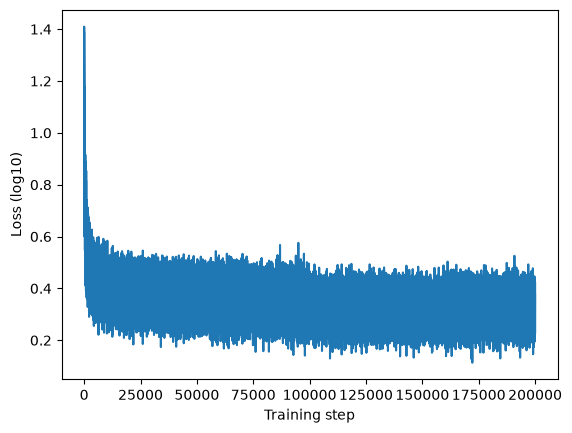

In [230]:
plt.plot(step_i, loss_i)
plt.xlabel('Training step')
plt.ylabel('Loss (log10)')

In [231]:
emb = C[Xtr] # (32, 3, 2)
h = torch.tanh(emb.view(-1, 30) @ W1 + b1) # (32, 100)
logits = h @ W2 + b2 # (32, 27)
loss = F.cross_entropy(logits, Ytr)
loss

tensor(2.1233, grad_fn=<NllLossBackward0>)

In [232]:
emb = C[Xdev] # (32, 3, 2)
h = torch.tanh(emb.view(-1, 30) @ W1 + b1) # (32, 100)
logits = h @ W2 + b2 # (32, 27)
loss = F.cross_entropy(logits, Ydev)
loss

tensor(2.1556, grad_fn=<NllLossBackward0>)

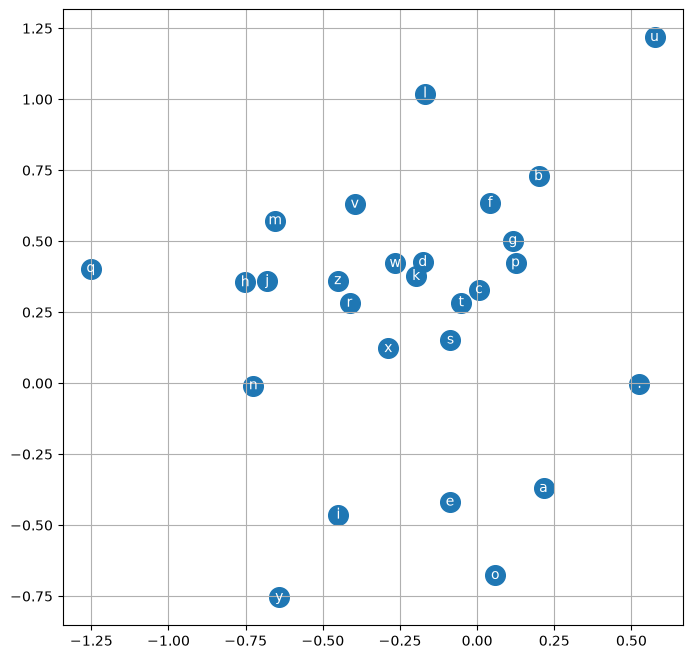

In [203]:
plt.figure(figsize=(8,8))
plt.scatter(C[:,0].data, C[:,1].data, s=200)
for i in range(C.shape[0]):
    plt.text(C[i,0].item(), C[i,1].item(), itos[i], ha="center", va="center", color='white')
plt.grid('minor')

In [233]:
# sample from the model
g = torch.Generator().manual_seed(2147483647 + 10)

for _ in range(20):
    
    out = []
    context = [0] * block_size # initialize with all ...
    while True:
      emb = C[torch.tensor([context])] # (1,block_size,d)
      h = torch.tanh(emb.view(1, -1) @ W1 + b1)
      logits = h @ W2 + b2
      probs = F.softmax(logits, dim=1)
      idx = torch.multinomial(probs, num_samples=1, generator=g).item()
      context = context[1:] + [idx]
      out.append(idx)
      if idx == 0:
        break
    
    print(''.join(itos[i] for i in out))

carmaizabelle.
khi.
mili.
thiyah.
cassie.
rahnen.
delynn.
jareei.
ner.
kentziriivia.
lege.
dham.
jorn.
quintis.
lilea.
vidai.
watelogiearyni.
fraegedruch.
edde.
ois.
